# Solution: Mission 01 — Operation Market Pulse

This notebook is one possible solution. Try the mission yourself before you read it. The solution uses only the topics of M01 Lessons 01–10: collections, comprehensions, loops, conditions, functions, file I/O and exception handling.

In [1]:
raw_orders = [
    {"store": "North", "item": "milk", "qty": "12", "priority": "high"},
    {"store": "North", "item": "bread", "qty": "8", "priority": "medium"},
    {"store": "South", "item": "eggs", "qty": "invalid", "priority": "high"},
    {"store": "East", "item": "apples", "qty": "20", "priority": "low"},
    {"store": "North", "item": "milk", "qty": "5", "priority": "high"},
    {"store": "West", "item": "coffee", "qty": "3", "priority": "urgent"},
    {"store": " south ", "item": "Eggs ", "qty": "6", "priority": "HIGH"},    # extra rows to test cleaning
    {"store": "East", "item": "bread", "priority": "low"},                      # missing qty
    {"store": "West", "item": "milk", "qty": "-4", "priority": "high"},        # negative qty
]
allowed_priorities = {"low", "medium", "high", "urgent"}
critical_items = {"milk", "eggs", "bread"}
REQUIRED_KEYS = ("store", "item", "qty", "priority")
PRIORITY_RANK = {"urgent": 0, "high": 1, "medium": 2, "low": 3}

## 1. Parse and Clean

`parse_order()` validates one row and raises a `ValueError` with a clear message. `clean_orders()` keeps the valid rows and collects the problems, so one bad row does not stop the workflow.

In [2]:
def parse_order(record: dict) -> dict:
    """Return a cleaned order dictionary or raise ValueError with the reason."""
    missing = [k for k in REQUIRED_KEYS if k not in record]
    if missing:
        raise ValueError(f"missing keys: {missing}")
    try:
        qty = int(record["qty"])
    except (TypeError, ValueError):
        raise ValueError(f"quantity {record['qty']!r} is not a number") from None
    if qty <= 0:
        raise ValueError(f"quantity must be positive, got {qty}")
    priority = record["priority"].strip().lower()
    if priority not in allowed_priorities:
        raise ValueError(f"invalid priority {record['priority']!r}")
    return {"store": record["store"].strip().title(), "item": record["item"].strip().lower(),
            "qty": qty, "priority": priority}


def clean_orders(records: list[dict]) -> tuple[list[dict], list[str]]:
    """Return (valid orders, problem messages)."""
    valid, problems = [], []
    for i, record in enumerate(records):
        try:
            valid.append(parse_order(record))
        except ValueError as err:
            problems.append(f"row {i}: {err}")
    return valid, problems


orders, problems = clean_orders(raw_orders)
print(f"{len(orders)} valid orders, {len(problems)} rejected")
for p in problems:
    print("  -", p)

6 valid orders, 3 rejected
  - row 2: quantity 'invalid' is not a number
  - row 7: missing keys: ['qty']
  - row 8: quantity must be positive, got -4


## 2. Summarise

The summary uses a dict comprehension (totals per store) and a list comprehension (critical items, sorted by priority).

In [3]:
from collections import Counter, defaultdict


def summarize_orders(orders: list[dict], critical_first: bool = True) -> dict:
    """Return store totals, critical item counts and the priority breakdown."""
    stores = sorted({o["store"] for o in orders})
    store_totals = {s: sum(o["qty"] for o in orders if o["store"] == s) for s in stores}   # dict comprehension
    item_totals = defaultdict(int)
    for o in orders:
        item_totals[o["item"]] += o["qty"]
    critical = [(item, qty) for item, qty in item_totals.items() if item in critical_items]  # list comprehension
    best_rank = {item: min(PRIORITY_RANK[o["priority"]] for o in orders if o["item"] == item) for item in item_totals}
    stock_order = sorted(item_totals, key=lambda it: (it not in critical_items if critical_first else 0,
                                                      best_rank[it], -item_totals[it]))
    return {"store_totals": store_totals, "critical": dict(critical),
            "priorities": dict(Counter(o["priority"] for o in orders)), "stock_first": stock_order}


summary = summarize_orders(orders)
summary

{'store_totals': {'East': 20, 'North': 25, 'South': 6, 'West': 3},
 'critical': {'milk': 17, 'bread': 8, 'eggs': 6},
 'priorities': {'high': 3, 'medium': 1, 'low': 1, 'urgent': 1},
 'stock_first': ['milk', 'eggs', 'bread', 'coffee', 'apples']}

## 3. Write the Report

The report is plain text that the manager can read in under one minute. The shift name is a function parameter instead of `input()`, so the notebook runs without waiting for a user.

In [4]:
import tempfile
from pathlib import Path


def write_report(path: Path, summary: dict, problems: list[str], shift_name: str = "Night shift") -> Path:
    lines = [f"PulseMart nightly report - {shift_name}", "=" * 40, "", "Stock first (in this order):"]
    lines += [f"  {i}. {item}" for i, item in enumerate(summary["stock_first"], start=1)]
    lines += ["", "Units per store:"] + [f"  {s:<6} {q:>4}" for s, q in summary["store_totals"].items()]
    lines += ["", "Critical items:"] + [f"  {it:<6} {q:>4}" for it, q in summary["critical"].items()]
    lines += ["", f"Rejected rows ({len(problems)}):"] + [f"  - {p}" for p in problems]
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return path


report = write_report(Path(tempfile.mkdtemp()) / "nightly_report.txt", summary, problems)
print(report.read_text(encoding="utf-8"))

PulseMart nightly report - Night shift

Stock first (in this order):
  1. milk
  2. eggs
  3. bread
  4. coffee
  5. apples

Units per store:
  East     20
  North    25
  South     6
  West      3

Critical items:
  milk     17
  bread     8
  eggs      6

Rejected rows (3):
  - row 2: quantity 'invalid' is not a number
  - row 7: missing keys: ['qty']
  - row 8: quantity must be positive, got -4



## 4. Bonus: Critical Items First or Not

The bonus asked for a choice between "critical items first" and a plain priority order. The flag is a parameter of `summarize_orders()`.

critical first : ['milk', 'eggs', 'bread', 'coffee', 'apples']
priority only  : ['coffee', 'milk', 'eggs', 'bread', 'apples']


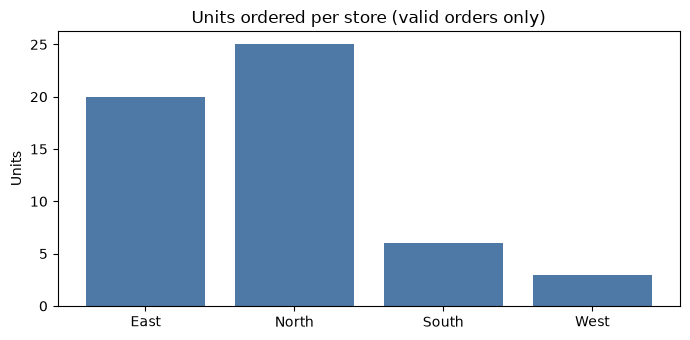

In [5]:
import matplotlib.pyplot as plt

print("critical first :", summarize_orders(orders, critical_first=True)["stock_first"])
print("priority only  :", summarize_orders(orders, critical_first=False)["stock_first"])

fig, ax = plt.subplots(figsize=(7, 3.5))
totals = summary["store_totals"]
ax.bar(totals.keys(), totals.values(), color="#4E79A7")
ax.set(title="Units ordered per store (valid orders only)", ylabel="Units")
plt.tight_layout()
plt.show()

## Checklist

- The notebook runs from top to bottom without user input.
- Invalid rows are reported with a reason; they do not stop the workflow.
- The report file is created and lists what to stock first.
- The solution uses a list comprehension, a dict comprehension, small functions and `try/except`.